# A/B Test: Does Moving a Progress Gate Hurt Retention?
**Public data:** *Cookie Cats* mobile-game experiment (90,189 players). Players were randomly assigned at install to a progress gate at **level 30 (control)** or **level 40 (treatment)**.

**Decision question:** should the gate move from level 30 to level 40?
**Primary metric:** 7-day retention · **Secondary:** 1-day retention · **Guardrail:** engagement (game rounds in the first 14 days)

Workflow: sanity checks (sample-ratio mismatch) → effect estimates with frequentist tests → bootstrap CIs → power / minimum detectable effect → recommendation.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid"); FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(42)

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
df = pd.read_csv("../data/cookie_cats.csv")
print(df.shape); df.head()

(90189, 5)


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Sanity checks

In [2]:
counts = df["version"].value_counts()
srm = stats.chisquare(counts.values)          # expected 50/50 split
print(counts.to_string()); print(f"Sample-ratio mismatch test: chi2={srm.statistic:.2f}, p={srm.pvalue:.3f}")
print("Duplicate user ids:", df["userid"].duplicated().sum())
print(df["sum_gamerounds"].describe().round(1).to_string())

version
gate_40    45489
gate_30    44700
Sample-ratio mismatch test: chi2=6.90, p=0.009
Duplicate user ids: 0
count    90189.0
mean        51.9
std        195.1
min          0.0
25%          5.0
50%         16.0
75%         51.0
max      49854.0


The split is close to 50/50 (44,700 vs. 45,489). The SRM test is significant (p = 0.009) because of the large N, but the 0.9% imbalance is small and plausibly due to the assignment mechanism; it is noted as a caveat rather than a blocker. `sum_gamerounds` has an extreme outlier (49,854 rounds) and a heavy right tail, so non-parametric tests are used for engagement.

## 2. Retention effect

In [3]:
rows = []
for metric in ["retention_1", "retention_7"]:
    g = df.groupby("version")[metric].agg(["sum", "count", "mean"])
    z, p = proportions_ztest(g["sum"].values, g["count"].values)
    lo, hi = confint_proportions_2indep(g.loc["gate_40", "sum"], g.loc["gate_40", "count"],
                                        g.loc["gate_30", "sum"], g.loc["gate_30", "count"])
    diff = g.loc["gate_40", "mean"] - g.loc["gate_30", "mean"]
    rows.append({"metric": metric, "gate_30": g.loc["gate_30", "mean"], "gate_40": g.loc["gate_40", "mean"],
                 "diff_pp": diff * 100, "ci95_pp": f"[{lo*100:.2f}, {hi*100:.2f}]",
                 "relative_change": diff / g.loc["gate_30", "mean"], "p_value": p})
effects = pd.DataFrame(rows).set_index("metric"); effects.round(4)

,gate_30,gate_40,diff_pp,ci95_pp,relative_change,p_value
metric,,,,,,
retention_1,0.4482,0.4423,-0.5905,"[-1.24, 0.06]",-0.0132,0.0744
retention_7,0.1902,0.1820,-0.8201,"[-1.33, -0.31]",-0.0431,0.0016


### Bootstrap confidence intervals

retention_1: bootstrap 95% CI [-1.25, 0.06] pp, P(diff<0) = 0.962
retention_7: bootstrap 95% CI [-1.33, -0.31] pp, P(diff<0) = 0.999


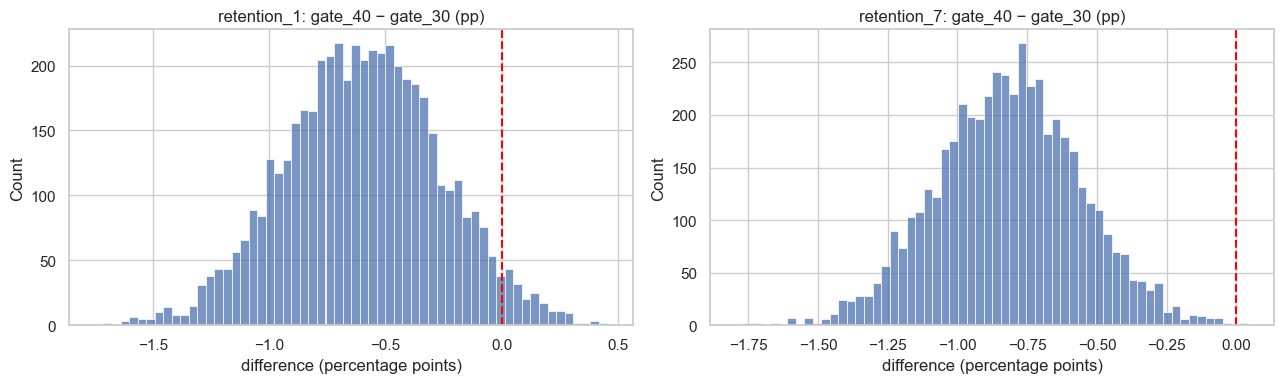

In [4]:
def bootstrap_diff(metric, n_boot=5000):
    a = df.loc[df.version == "gate_30", metric].values.astype(float)
    b = df.loc[df.version == "gate_40", metric].values.astype(float)
    ma = rng.binomial(len(a), a.mean(), n_boot) / len(a)      # parametric bootstrap of a proportion
    mb = rng.binomial(len(b), b.mean(), n_boot) / len(b)
    return (mb - ma) * 100

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for i, m in enumerate(["retention_1", "retention_7"]):
    d = bootstrap_diff(m)
    sns.histplot(d, ax=ax[i], bins=60); ax[i].axvline(0, color="red", ls="--")
    ax[i].set(title=f"{m}: gate_40 − gate_30 (pp)", xlabel="difference (percentage points)")
    print(f"{m}: bootstrap 95% CI [{np.percentile(d,2.5):.2f}, {np.percentile(d,97.5):.2f}] pp, P(diff<0) = {(d<0).mean():.3f}")
plt.tight_layout(); plt.savefig(FIG / "ab_bootstrap.png", dpi=130); plt.show()

## 3. Guardrail: engagement

In [5]:
a = df.loc[df.version == "gate_30", "sum_gamerounds"]; b = df.loc[df.version == "gate_40", "sum_gamerounds"]
mw = stats.mannwhitneyu(a, b)
print(f"Median rounds: gate_30={a.median():.0f}, gate_40={b.median():.0f}; Mann-Whitney p={mw.pvalue:.3f}")

Median rounds: gate_30=17, gate_40=16; Mann-Whitney p=0.050


## 4. Power and minimum detectable effect

In [6]:
n = int(counts.min()); base = effects.loc["retention_7", "gate_30"]
power = NormalIndPower()
for mde_pp in [0.5, 0.8, 1.0, 1.5]:
    es = proportion_effectsize(base, base - mde_pp / 100)
    print(f"MDE {mde_pp:.1f} pp → power {power.power(es, nobs1=n, alpha=0.05):.2f}")
need = power.solve_power(proportion_effectsize(base, base - 0.005), power=0.8, alpha=0.05)
print(f"Users per arm needed to detect a 0.5 pp drop with 80% power: {need:,.0f}")

MDE 0.5 pp → power 0.48
MDE 0.8 pp → power 0.87
MDE 1.0 pp → power 0.97
MDE 1.5 pp → power 1.00
Users per arm needed to detect a 0.5 pp drop with 80% power: 95,733


## 5. Recommendation
- **7-day retention is 0.82 pp lower with the gate at level 40** (19.0% → 18.2%, −4.3% relative, p ≈ 0.002; the bootstrap puts >99% of the mass below zero).
- 1-day retention is directionally lower (−0.59 pp) but not significant at α = 0.05.
- Engagement shows a small, borderline decline (median 17 → 16 game rounds, Mann-Whitney p = 0.05), pointing the same direction as retention.
- The test is well powered for effects of ~0.8 pp and above.

**Decision: keep the gate at level 30.** Moving it later reduces week-one retention, the metric most tied to long-term value. Caveat: a slight sample-ratio imbalance (0.9%) should be investigated with the assignment service before the result is reused.